In [22]:
!pip list | grep transformers
!pip list | grep ms-swift
!nvidia-smi

transformers                      4.57.3
transformers-stream-generator     0.0.5
ms_swift                          4.2.0.dev0     /home/hadoop-risk-control-algo/dolphinfs_hdd_hadoop-risk-control-algo/prime/zhangyue230/ms-swift
Wed Nov  4 14:16:07 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.105.08             Driver Version: 580.105.08     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA A800-SXM4-80GB          On  |   00000000:0E:00.0 Off |                    0 |
| N/A

## ChartNet summary：Adapter 训练

计划见 `README.md`。下面三个单元依次是：导出 jsonl、插入 adapter 并训练、画出 loss 和学习率。

上面的整模加载会占满 8 张 GPU。导出可以在当前内核先跑，它只写磁盘。训练前重启内核，不要再跑 `from_pretrained`，否则 swift 会再加载一份 7B。


In [2]:
# 把 Arrow 样本写成 ms-swift 支持的 jsonl格式。
# datasets 读 image 列；swift 的 sft_main 需要 messages + 图片路径，与PEFT的 Arrow 不同。
import json
from pathlib import Path

from datasets import load_from_disk

ROOT = Path("/home/hadoop-risk-control-algo/dolphinfs_hdd_hadoop-risk-control-algo/heguihong/PEFT")
DATA_DIR = ROOT / "data" / "chartnet_sample"
EXPORT_DIR = ROOT / "data" / "chartnet_swift"
IMAGE_DIR = EXPORT_DIR / "images"

# 与 README 第 2 节同一套提示词。summary 是英文，所以 system / user 也用英文。
# 显式写入 system：qwen2_5_vl 模板在缺省时会自动补 "You are a helpful assistant."，没有图表任务约束。
SYSTEM_TEXT = (
    "You are a chart understanding assistant. Read the single chart in the image and write a detailed English summary. "
    "Describe the chart type, title, axes, legends, and the trends, comparisons, or distributions that are visible. "
    "Use only what the image shows. Do not output code, CSV, or a data table."
)
# <image> 是 swift 的占位符，编码时换成 <|vision_start|><|image_pad|><|vision_end|>。
USER_TEXT = "<image>\nWrite a detailed summary of this chart."
# 从 test 的 1000 条里固定抽 450 条做验证。train 用全部 4000 条。
EVAL_SIZE = 450
EVAL_SEED = 42


def export_split(split, dest_jsonl, limit=None, seed=EVAL_SEED):
    """导出一个 split。limit 不为空时先按 seed 打乱再截取，保证 eval 集合固定。"""
    ds = load_from_disk(str(DATA_DIR / split))
    if limit is not None:
        ds = ds.shuffle(seed=seed).select(range(limit))
    image_dir = IMAGE_DIR / split
    image_dir.mkdir(parents=True, exist_ok=True)
    wrote = 0
    with dest_jsonl.open("w", encoding="utf-8") as f:
        for row in ds:
            # id 只用于文件名，不进 prompt。code、csv 整列丢弃。
            image_path = image_dir / f"{row['id']}.png"
            if not image_path.exists():
                row["image"].save(image_path)
            record = {
                "messages": [
                    {"role": "system", "content": SYSTEM_TEXT},
                    {"role": "user", "content": USER_TEXT},
                    {"role": "assistant", "content": row["summary"]},
                ],
                "images": [str(image_path)],
            }
            f.write(json.dumps(record, ensure_ascii=False) + "\n")
            wrote += 1
    print(split, wrote, dest_jsonl)
    return wrote


EXPORT_DIR.mkdir(parents=True, exist_ok=True)
train_jsonl = EXPORT_DIR / "train.jsonl"
eval_jsonl = EXPORT_DIR / "eval.jsonl"
# 已有 PNG 会跳过，jsonl 每次按当前模板重写。
export_split("train", train_jsonl)
export_split("test", eval_jsonl, limit=EVAL_SIZE)

# 打印第一条，核对 system / user / assistant 和图片是否齐全。
sample = json.loads(train_jsonl.read_text(encoding="utf-8").splitlines()[0])
print("roles", [m["role"] for m in sample["messages"]])
print("user", repr(sample["messages"][1]["content"]))
print("image", sample["images"][0], "summary_chars", len(sample["messages"][2]["content"]))


train 4000 /home/hadoop-risk-control-algo/dolphinfs_hdd_hadoop-risk-control-algo/heguihong/PEFT/data/chartnet_swift/train.jsonl
test 450 /home/hadoop-risk-control-algo/dolphinfs_hdd_hadoop-risk-control-algo/heguihong/PEFT/data/chartnet_swift/eval.jsonl
roles ['system', 'user', 'assistant']
user '<image>\nWrite a detailed summary of this chart.'
image /home/hadoop-risk-control-algo/dolphinfs_hdd_hadoop-risk-control-algo/heguihong/PEFT/data/chartnet_swift/images/train/98a546531683af2c.png summary_chars 1779


In [3]:
# Houlsby bottleneck adapter 微调。只训练新插入的模块，基座权重冻结。
# 运行前请重启内核，并且不要重跑上面的 from_pretrained。
import gc
import os
import re

import torch

ROOT = "/home/hadoop-risk-control-algo/dolphinfs_hdd_hadoop-risk-control-algo/heguihong/PEFT"
TRAIN_JSONL = f"{ROOT}/data/chartnet_swift/train.jsonl"
EVAL_JSONL = f"{ROOT}/data/chartnet_swift/eval.jsonl"
MODEL_ID = "/mnt/dolphinfs/hdd_pool/docker/user/hadoop-risk-control-algo/yinyanling02/code/llm-qwen/Qwen2.5-VL-main/Qwen/Qwen2.5-VL-7B-Instruct"
OUTPUT_DIR = f"{ROOT}/outputs/chartnet_summary_adapter"

# checkpoint 默认 max_pixels=12845056，约 1.6 万视觉 token，会撑爆显存。
# 1003520 ≈ 1280 个视觉 token（每个 token 对应 28×28 像素）。
# qwen_vl_utils 读环境变量，SftArguments.max_pixels 给 swift 模板，两处都要设。
MAX_PIXELS = 1003520
os.environ["MAX_PIXELS"] = str(MAX_PIXELS)
os.environ["MIN_PIXELS"] = "3136"

# 若上面的整模还在这个内核里，先丢掉引用。分卡加载的显存要重启内核才能真正释放。
for _name in ("base_model", "processor"):
    if _name in globals():
        del globals()[_name]
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

import swift.pipelines.train.tuner as tuner_mod
from swift.arguments import SftArguments
from swift.pipelines.train.sft import sft_main
from swift.tuners import AdapterConfig, Swift
from swift.tuners.adapter import AdapterModule

# 源码对 linear1、linear2 都做 Xavier。Houlsby 要求升维矩阵接近 0，
# 这样训练第 0 步的残差输出仍等于原 MLP 输出。
_orig_init = AdapterModule.init_weights


def _near_identity_init(self):
    _orig_init(self)
    torch.nn.init.zeros_(self.linear2.weight)
    if self.linear2.bias is not None:
        torch.nn.init.zeros_(self.linear2.bias)


AdapterModule.init_weights = _near_identity_init

# 默认 prepare_adapter 读 model_arch.mlp。qwen2_vl 这个字段是 None，会直接报错。
# 即便补上名字，endswith("mlp") 还会匹配视觉塔 MLP（宽度 1280），
# 而 AdapterConfig.dim 只有语言模型的 3584。这里改成整段正则，只挂 28 层语言模型 MLP。
# 这一版 swift 的 adapter 只插在 MLP 输出上（Pfeiffer 放置），注意力子层后面没有第二个。
_orig_prepare = tuner_mod.prepare_adapter


def _prepare_language_mlp_adapter(args, model, *a, **k):
    if args.tuner_type != "adapter":
        return _orig_prepare(args, model, *a, **k)
    hidden = model.config.hidden_size
    config = AdapterConfig(
        dim=hidden,
        target_modules=r"model\.language_model\.layers\.\d+\.mlp",
        hidden_pos=0,  # MLP.forward 的第一个返回值就是 hidden state
        adapter_length=args.adapter_length,
        act_layer=args.adapter_act,
    )
    model = Swift.prepare_model(model, config)  # 先冻结全部参数，再把 adapter 设为可训练
    n_adapter = sum(1 for name, _ in model.named_modules() if name.endswith("adapter_default"))
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"adapter hidden={hidden} modules={n_adapter} trainable={trainable / 1e6:.2f}M")
    return model


tuner_mod.prepare_adapter = _prepare_language_mlp_adapter

args = SftArguments(
    model=MODEL_ID,
    model_type="qwen2_5_vl",
    template="qwen2_5_vl",
    tuner_type="adapter",
    adapter_length=128,   # 瓶颈维。28 层约 2570 万参数
    adapter_act="gelu",
    dataset=[TRAIN_JSONL],
    val_dataset=[EVAL_JSONL],
    split_dataset_ratio=0.0,  # 验证集单独给，不从 train 再切
    dataset_num_proc=1,
    max_length=3072,
    max_pixels=MAX_PIXELS,
    loss_scale="default",  # 交叉熵只算 assistant 的 summary，system / user / 图像 token 不算
    torch_dtype="bfloat16",
    bf16=True,
    gradient_checkpointing=True,
    per_device_train_batch_size=1,  # 模型已按 device_map 摊到 8 卡，不能再开 DDP
    per_device_eval_batch_size=1,
    gradient_accumulation_steps=8,  # 有效 batch = 8
    num_train_epochs=2,             # 4000 / 8 * 2 = 1000 optimizer step
    learning_rate=1e-4,
    lr_scheduler_type="cosine",
    warmup_ratio=0.03,
    weight_decay=0.01,
    max_grad_norm=1.0,
    logging_steps=10,
    eval_strategy="steps",
    eval_steps=100,
    save_strategy="steps",
    save_steps=200,
    save_total_limit=2,             # 只留 2 个 checkpoint，保存的是 adapter 而不是整模
    report_to=["tensorboard"],
    output_dir=OUTPUT_DIR,
    add_version=False,              # 目录名固定，不追加版本号
    seed=42,
    dataloader_num_workers=2,
    dataloader_pin_memory=True,
)
sft_main(args)


[INFO:swift] Successfully registered `/home/hadoop-risk-control-algo/dolphinfs_hdd_hadoop-risk-control-algo/prime/zhangyue230/ms-swift/swift/dataset/data/dataset_info.json`.
2026-11-03 13:36:31,283	INFO util.py:154 -- Outdated packages:
  ipywidgets==8.0.0b0 found, needs ipywidgets>=8
Run `pip install -U ipywidgets`, then restart the notebook server for rich notebook output.
[INFO:swift] rank: -1, local_rank: -1, world_size: 1, local_world_size: 1
`torch_dtype` is deprecated! Use `dtype` instead!
[WARNING:swift] Please install the package: `pip install "decord" -U`.
[INFO:swift] Because len(args.val_dataset) > 0, setting split_dataset_ratio: 0.0
[INFO:swift] Setting args.lazy_tokenize: True
[INFO:swift] args: SftArguments(
_n_gpu=-1,
acc_strategy=token,
accelerator_config={'dispatch_batches': False},
adafactor=False,
adalora_beta1=0.85,
adalora_beta2=0.85,
adalora_deltaT=1,
adalora_init_r=12,
adalora_orth_reg_weight=0.5,
adalora_target_r=8,
adalora_tfinal=0,
adalora_tinit=0,
adam_beta1

Loading checkpoint shards:   0%|          | 0/5 [00:00<?, ?it/s]

[INFO:swift] model.hf_device_map: {'model.visual': 0, 'model.language_model.embed_tokens': 1, 'model.language_model.layers.0': 1, 'model.language_model.layers.1': 1, 'model.language_model.layers.2': 1, 'model.language_model.layers.3': 2, 'model.language_model.layers.4': 2, 'model.language_model.layers.5': 2, 'model.language_model.layers.6': 2, 'model.language_model.layers.7': 2, 'model.language_model.layers.8': 3, 'model.language_model.layers.9': 3, 'model.language_model.layers.10': 3, 'model.language_model.layers.11': 3, 'model.language_model.layers.12': 3, 'model.language_model.layers.13': 4, 'model.language_model.layers.14': 4, 'model.language_model.layers.15': 4, 'model.language_model.layers.16': 4, 'model.language_model.layers.17': 4, 'model.language_model.layers.18': 5, 'model.language_model.layers.19': 5, 'model.language_model.layers.20': 5, 'model.language_model.layers.21': 5, 'model.language_model.layers.22': 5, 'model.language_model.layers.23': 6, 'model.language_model.layers

Generating train split: 0 examples [00:00, ? examples/s]

Map:   0%|          | 0/4000 [00:00<?, ? examples/s]

Generating train split: 0 examples [00:00, ? examples/s]

... (225 outputs left out)

[INFO:swift] Saving model checkpoint to /home/hadoop-risk-control-algo/dolphinfs_hdd_hadoop-risk-control-algo/heguihong/PEFT/outputs/chartnet_summary_adapter/checkpoint-1000
Train: 100%|██████████| 1000/1000 [1:57:00<00:00,  7.02s/it]
[INFO:swift] last_model_checkpoint: /home/hadoop-risk-control-algo/dolphinfs_hdd_hadoop-risk-control-algo/heguihong/PEFT/outputs/chartnet_summary_adapter/checkpoint-1000
[INFO:swift] best_model_checkpoint: /home/hadoop-risk-control-algo/dolphinfs_hdd_hadoop-risk-control-algo/heguihong/PEFT/outputs/chartnet_summary_adapter/checkpoint-1000
[INFO:swift] images_dir: /home/hadoop-risk-control-algo/dolphinfs_hdd_hadoop-risk-control-algo/heguihong/PEFT/outputs/chartnet_summary_adapter/images


{'train_runtime': 7020.5506, 'train_samples_per_second': 1.14, 'train_steps_per_second': 0.142, 'train_loss': 0.45946798, 'epoch': 2.0, 'global_step/max_steps': '1000/1000', 'elapsed_time': '1h 57m 1s', 'remaining_time': '0s', 'memory(GiB)': 84.19, 'train_speed(s/it)': 7.020544}


[INFO:swift] End time of running main: 2026-11-03 15:33:57.265353


{'model_parameter_info': 'SwiftModel: 8317.9607M Params (25.7940M Trainable [0.3101%]), 0.0019M Buffers.',
 'last_model_checkpoint': '/home/hadoop-risk-control-algo/dolphinfs_hdd_hadoop-risk-control-algo/heguihong/PEFT/outputs/chartnet_summary_adapter/checkpoint-1000',
 'best_model_checkpoint': '/home/hadoop-risk-control-algo/dolphinfs_hdd_hadoop-risk-control-algo/heguihong/PEFT/outputs/chartnet_summary_adapter/checkpoint-1000',
 'best_metric': 0.45238519,
 'global_step': 1000,
 'log_history': [{'loss': 0.7604511976242065,
   'grad_norm': 0.9061378836631775,
   'learning_rate': 3.3333333333333333e-06,
   'token_acc': 0.770962962962963,
   'epoch': 0.002,
   'step': 1},
  {'loss': 0.7508899900648329,
   'grad_norm': 0.633590817451477,
   'learning_rate': 3.3333333333333335e-05,
   'token_acc': 0.7770016815418446,
   'epoch': 0.02,
   'step': 10},
  {'loss': 0.6438079357147217,
   'grad_norm': 0.48701921105384827,
   'learning_rate': 6.666666666666667e-05,
   'token_acc': 0.8048064010743

In [4]:
# 从 trainer_state.json 的 log_history 画三条曲线。
# swift 结束时只会用 TensorBoard 画 train/loss，eval loss 和学习率要在这里补。
import json
from pathlib import Path

import matplotlib.pyplot as plt

OUTPUT_DIR = Path("/home/hadoop-risk-control-algo/dolphinfs_hdd_hadoop-risk-control-algo/heguihong/PEFT/outputs/chartnet_summary_adapter")


def load_history(output_dir: Path):
    direct = output_dir / "trainer_state.json"
    if direct.exists():
        return json.loads(direct.read_text())["log_history"], direct
    # 有的版本只把 state 写在 checkpoint 目录里，取 step 最大的那份。
    found = sorted(output_dir.rglob("trainer_state.json"))
    if found:
        path = found[-1]
        return json.loads(path.read_text())["log_history"], path
    # sft_main 还会把最后一次 log_history 写进 logging.jsonl。
    logging_path = output_dir / "logging.jsonl"
    if logging_path.exists():
        last = json.loads(logging_path.read_text().splitlines()[-1])
        return last["log_history"], logging_path
    raise FileNotFoundError(f"no training log under {output_dir}")


history, state_path = load_history(OUTPUT_DIR)
print("log", state_path, "records", len(history))

train_steps = [x["step"] for x in history if "loss" in x]
train_loss = [x["loss"] for x in history if "loss" in x]
eval_steps = [x["step"] for x in history if "eval_loss" in x]
eval_loss = [x["eval_loss"] for x in history if "eval_loss" in x]
lrs = [(x["step"], x["learning_rate"]) for x in history if "learning_rate" in x]

fig_dir = OUTPUT_DIR / "images"
fig_dir.mkdir(parents=True, exist_ok=True)


def save_curve(xs, ys, ylabel, title, filename):
    plt.figure()
    plt.plot(xs, ys)
    plt.xlabel("step")
    plt.ylabel(ylabel)
    plt.title(title)
    plt.tight_layout()
    path = fig_dir / filename
    plt.savefig(path)
    plt.close()
    print(path, "points", len(xs))


save_curve(train_steps, train_loss, "train loss", "ChartNet adapter train loss", "train_loss.png")
save_curve(eval_steps, eval_loss, "eval loss", "ChartNet adapter eval loss, 450 test rows", "eval_loss.png")
if lrs:
    save_curve([s for s, _ in lrs], [v for _, v in lrs], "learning rate", "ChartNet adapter learning rate", "learning_rate.png")


log /home/hadoop-risk-control-algo/dolphinfs_hdd_hadoop-risk-control-algo/heguihong/PEFT/outputs/chartnet_summary_adapter/checkpoint-800/trainer_state.json records 89
/home/hadoop-risk-control-algo/dolphinfs_hdd_hadoop-risk-control-algo/heguihong/PEFT/outputs/chartnet_summary_adapter/images/train_loss.png points 81
/home/hadoop-risk-control-algo/dolphinfs_hdd_hadoop-risk-control-algo/heguihong/PEFT/outputs/chartnet_summary_adapter/images/eval_loss.png points 8
/home/hadoop-risk-control-algo/dolphinfs_hdd_hadoop-risk-control-algo/heguihong/PEFT/outputs/chartnet_summary_adapter/images/learning_rate.png points 81


id: e41055fb3edeb15e
候选池: 550 张（test 1000 张，去掉验证集 450 张）
image: (2971, 1770) RGBA

===== system =====
You are a chart understanding assistant. Read the single chart in the image and write a detailed English summary. Describe the chart type, title, axes, legends, and the trends, comparisons, or distributions that are visible. Use only what the image shows. Do not output code, CSV, or a data table.

===== user =====
<image>
Write a detailed summary of this chart.


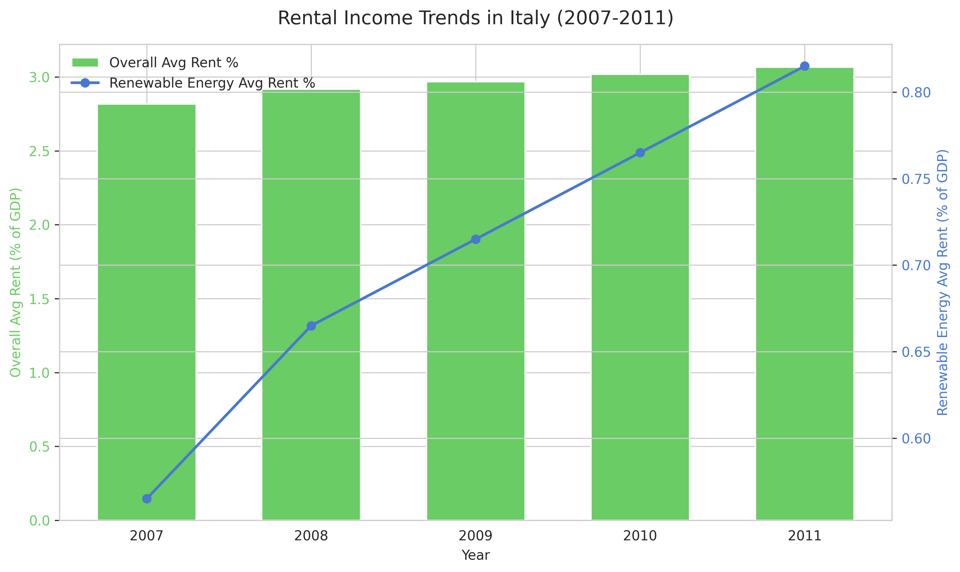


生成原模型输出...

===== 原模型 =====
The chart titled "Rental Income Trends in Italy (2007-2011)" presents a comparison between the overall average rent as a percentage of GDP and the average rent for properties with renewable energy features over the years 2007 to 2011.

**Axes:**
- The x-axis represents the years from 2007 to 2011.
- The y-axis on the left side is labeled "Overall Avg Rent (% of GDP)" and measures the percentage of GDP contributed by rental income.
- The y-axis on the right side is labeled "Renewable Energy Avg Rent (% of GDP)" and measures the percentage of GDP contributed by rental income specifically from properties with renewable energy features.

**Legend:**
- Green bars represent the "Overall Avg Rent %."
- Blue line with circular markers represents the "Renewable Energy Avg Rent %."

**Trends and Comparisons:**
- The green bars show a consistent increase in the overall average rent as a percentage of GDP across all years, starting at approximately 2.8% in 2007 and rea

In [13]:
# 从 test 里抽一条没有进入验证集 450 的图，对比基座和微调后的输出。
# 第一次运行会加载模型并挂上 checkpoint-1000；之后再跑这个单元只换样本，不重新加载。
import gc
import json
import os
import secrets
from pathlib import Path

import torch
from datasets import load_from_disk
from IPython.display import display
from swift.infer_engine import InferRequest, RequestConfig, TransformersEngine
from swift.template.base import Template
from swift.tuners import SwiftModel

# swift 的 get_base_model 只拆 PeftModel。Adapter 包的是 SwiftModel，拆不开时
# _get_position_ids 会在 Qwen2_5_VLForConditionalGeneration 上找 get_rope_index。
# 当前 transformers 把这个函数放在内层 Qwen2_5_VLModel（外层的 .model）上。
# 每次运行直接装上这段，不再调用上一轮已经替换过的函数，避免第二次运行递归。
def _unwrap_base_model(model):
    from peft import PeftModel
    if isinstance(model, PeftModel):
        model = model.model
    while isinstance(model, SwiftModel):
        model = model.base_model
    return model


Template.get_base_model = staticmethod(_unwrap_base_model)

ROOT = Path("/home/hadoop-risk-control-algo/dolphinfs_hdd_hadoop-risk-control-algo/heguihong/PEFT")
EVAL_JSONL = ROOT / "data" / "chartnet_swift" / "eval.jsonl"
MODEL_ID = "/mnt/dolphinfs/hdd_pool/docker/user/hadoop-risk-control-algo/yinyanling02/code/llm-qwen/Qwen2.5-VL-main/Qwen/Qwen2.5-VL-7B-Instruct"
CKPT = ROOT / "outputs" / "chartnet_summary_adapter" / "checkpoint-1000"

# 和训练相同的分辨率上限。qwen_vl_utils 读这两个环境变量。
os.environ["MAX_PIXELS"] = "1003520"
os.environ["MIN_PIXELS"] = "3136"

SYSTEM_TEXT = (
    "You are a chart understanding assistant. Read the single chart in the image and write a detailed English summary. "
    "Describe the chart type, title, axes, legends, and the trends, comparisons, or distributions that are visible. "
    "Use only what the image shows. Do not output code, CSV, or a data table."
)
USER_TEXT = "<image>\nWrite a detailed summary of this chart."

# eval.jsonl 就是训练时用的那 450 条，用图片文件名里的 id 排除它们。
eval_ids = set()
with EVAL_JSONL.open(encoding="utf-8") as f:
    for line in f:
        eval_ids.add(Path(json.loads(line)["images"][0]).stem)

test_ds = load_from_disk(str(ROOT / "data" / "chartnet_sample" / "test"))
test_ids = test_ds["id"]
holdout = [i for i, sample_id in enumerate(test_ids) if sample_id not in eval_ids]
if not holdout:
    raise RuntimeError("test 中没有验证集 450 之外的样本")

# secrets 不吃随机种子，所以不会被训练时的 seed 42 固定。
# 若上一次刚看过某条，这次从其余样本里再抽，连续两次点运行不会是同一张图。
last_id = globals().get("compare_last_id")
pool = [i for i in holdout if test_ids[i] != last_id] or holdout
row = test_ds[int(secrets.choice(pool))]
compare_last_id = row["id"]

if "compare_engine" not in globals():
    # 前面的 from_pretrained 若还占着显存，这里再加载一份 7B 会失败。
    for _name in ("base_model", "processor"):
        if _name in globals():
            del globals()[_name]
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    compare_engine = TransformersEngine(
        MODEL_ID,
        adapters=[str(CKPT)],
        torch_dtype=torch.bfloat16,
        model_type="qwen2_5_vl",
        device_map="auto",
    )
    print("loaded", type(compare_engine.model).__name__, "adapter", CKPT.name)

request = InferRequest(
    messages=[
        {"role": "system", "content": SYSTEM_TEXT},
        {"role": "user", "content": USER_TEXT},
    ],
    images=[row["image"]],  # 传原图，swift 会按 MAX_PIXELS 缩放
)
# temperature=0 会走贪心解码，两边的差别只来自 adapter。
config = RequestConfig(max_tokens=1280, temperature=0)


def _text(response):
    choice = response.choices[0]
    text = choice.message.content or ""
    if choice.finish_reason == "length":
        text += "\n\n[输出在 1280 token 处被截断]"
    return text


print("id:", row["id"])
print("候选池:", len(holdout), "张（test", len(test_ids), "张，去掉验证集", len(eval_ids), "张）")
print("image:", row["image"].size, row["image"].mode)
print("\n===== system =====\n" + SYSTEM_TEXT)
print("\n===== user =====\n" + USER_TEXT)
preview = row["image"].copy()
preview.thumbnail((960, 960))  # 只缩小笔记本里的预览，不改送给模型的图
display(preview)

print("\n生成原模型输出...")
# adapter 关闭后，MLP 上的瓶颈直接返回原输出，相当于未微调的基座。
with compare_engine.model.disable_adapter():
    base_text = _text(compare_engine.infer([request], config, use_tqdm=False)[0])
print("\n===== 原模型 =====\n" + base_text)

print("\n生成微调后输出...")
tuned_text = _text(compare_engine.infer([request], config, use_tqdm=False)[0])
print("\n===== 微调后 =====\n" + tuned_text)
print("\n===== 参考 summary =====\n" + row["summary"])
